In [1]:

!pip install pandas numpy matplotlib seaborn openpyxl

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

sns.set_theme(style="whitegrid")


All libraries imported successfully!


In [3]:

df = pd.read_csv('/content/retail_sales_dataset.csv')

print("Dataset loaded successfully!")
print(df.head())


Dataset loaded successfully!
   Transaction ID        Date Customer ID  Gender  Age Product Category  \
0               1  2023-11-24     CUST001    Male   34           Beauty   
1               2  2023-02-27     CUST002  Female   26         Clothing   
2               3  2023-01-13     CUST003    Male   50      Electronics   
3               4  2023-05-21     CUST004    Male   37         Clothing   
4               5  2023-05-06     CUST005    Male   30           Beauty   

   Quantity  Price per Unit  Total Amount  
0         3              50           150  
1         2             500          1000  
2         1              30            30  
3         1             500           500  
4         2              50           100  


In [4]:

print("Number of rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())


Number of rows and columns: (1000, 9)

Column names:
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']


In [5]:
print("Dataset information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB

Missing values in each column:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Duplicate rows: 0


In [6]:
df.describe(include='all')

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
count,1000.000000,1000,1000,1000,1000.00000,1000,1000.000000,1000.000000,1000.000000
unique,NaN,345,1000,2,NaN,3,NaN,NaN,NaN
top,NaN,2023-05-16,CUST001,Female,NaN,Clothing,NaN,NaN,NaN
freq,NaN,11,1,510,NaN,351,NaN,NaN,NaN
mean,500.500000,NaN,NaN,NaN,41.39200,NaN,2.514000,179.890000,456.000000
std,288.819436,NaN,NaN,NaN,13.68143,NaN,1.132734,189.681356,559.997632
min,1.000000,NaN,NaN,NaN,18.00000,NaN,1.000000,25.000000,25.000000
25%,250.750000,NaN,NaN,NaN,29.00000,NaN,1.000000,30.000000,60.000000
50%,500.500000,NaN,NaN,NaN,42.00000,NaN,3.000000,50.000000,135.000000
75%,750.250000,NaN,NaN,NaN,53.00000,NaN,4.000000,300.000000,900.000000


In [7]:
# Convert Date column into datetime format
df['Date'] = pd.to_datetime(df['Date'])

# Create Month and Quarter columns
df['Month'] = df['Date'].dt.month
df['Quarter'] = df['Date'].dt.quarter

# Display updated dataset
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount,Month,Quarter
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150,11,4
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000,2,1
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30,1,1
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500,5,2
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100,5,2


In [8]:
# Select numerical columns
numerical_columns = [
    'Age',
    'Quantity',
    'Price per Unit',
    'Total Amount'
]

# Calculate statistics
statistics = df[numerical_columns].agg(
    ['mean', 'median', 'std']
).T

# Add mode separately
statistics['mode'] = df[numerical_columns].mode().iloc[0]

print("Descriptive Statistics:")
display(statistics)

Descriptive Statistics:


,mean,median,std,mode
Age,41.392,42.0,13.681430,43.0
Quantity,2.514,3.0,1.132734,4.0
Price per Unit,179.890,50.0,189.681356,50.0
Total Amount,456.000,135.0,559.997632,50.0


In [9]:
category_sales = df.groupby('Product Category')['Total Amount'].sum()

print("Total Sales by Product Category:")
display(category_sales)

Total Sales by Product Category:


,Total Amount
Product Category,
Beauty,143515
Clothing,155580
Electronics,156905


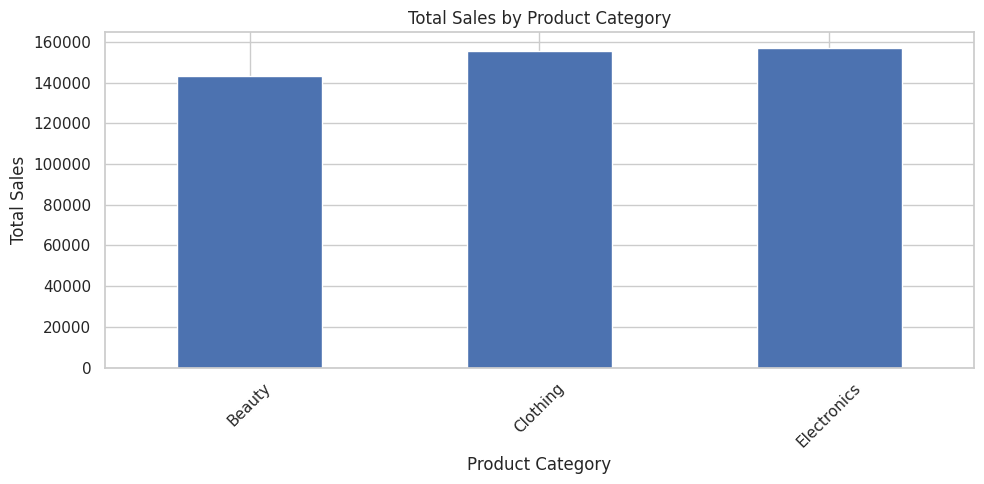

In [10]:
plt.figure(figsize=(10, 5))

category_sales.plot(kind='bar')

plt.title('Total Sales by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [11]:
# Calculate total sales for each month
monthly_sales = df.groupby('Month')['Total Amount'].sum()

print("Monthly Sales:")
display(monthly_sales)

Monthly Sales:


,Total Amount
Month,
1,36980
2,44060
3,28990
4,33870
5,53150
6,36715
7,35465
8,36960
9,23620


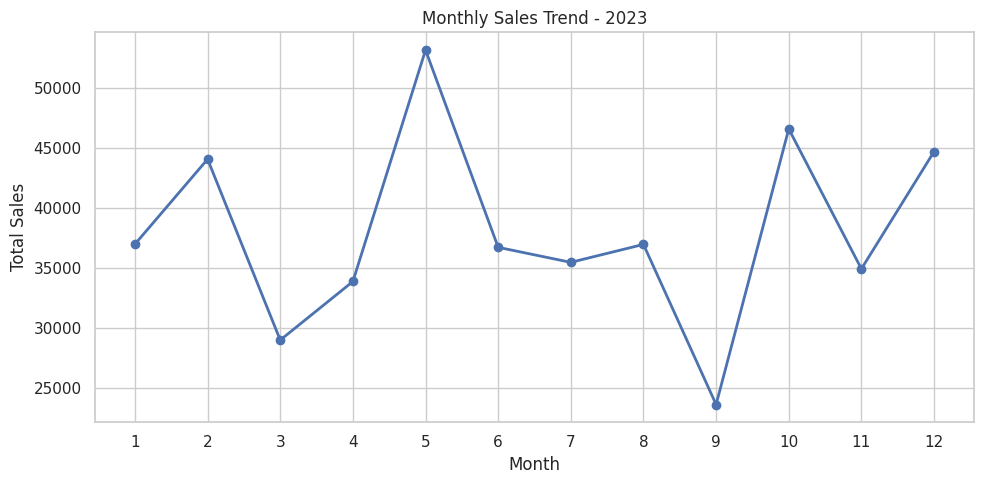

In [12]:
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker='o',
    linewidth=2
)

plt.title('Monthly Sales Trend - 2023')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(range(1, 13))
plt.grid(True)
plt.tight_layout()
plt.show()

In [13]:
# Calculate total sales for each quarter
quarterly_sales = df.groupby('Quarter')['Total Amount'].sum()

print("Quarterly Sales:")
display(quarterly_sales)

Quarterly Sales:


,Total Amount
Quarter,
1,110030
2,123735
3,96045
4,126190


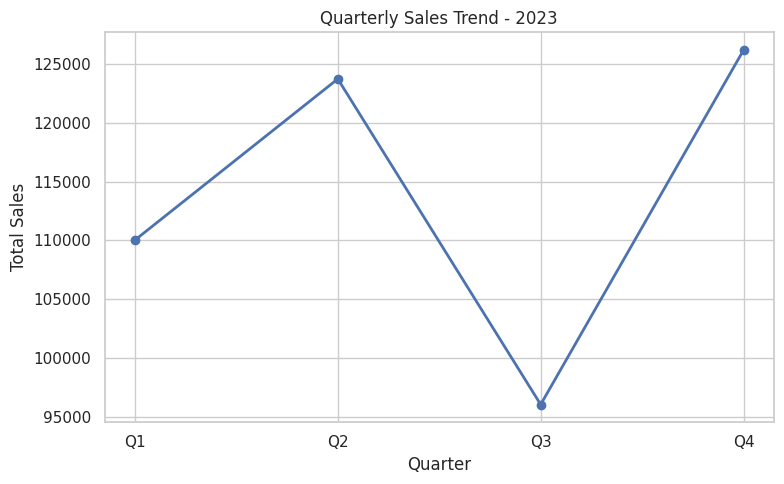

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(
    quarterly_sales.index,
    quarterly_sales.values,
    marker='o',
    linewidth=2
)

plt.title('Quarterly Sales Trend - 2023')
plt.xlabel('Quarter')
plt.ylabel('Total Sales')
plt.xticks([1, 2, 3, 4], ['Q1', 'Q2', 'Q3', 'Q4'])
plt.grid(True)
plt.tight_layout()
plt.show()

In [15]:
gender_count = df['Gender'].value_counts()

print("Customer Count by Gender:")
display(gender_count)

Customer Count by Gender:


,count
Gender,
Female,510
Male,490


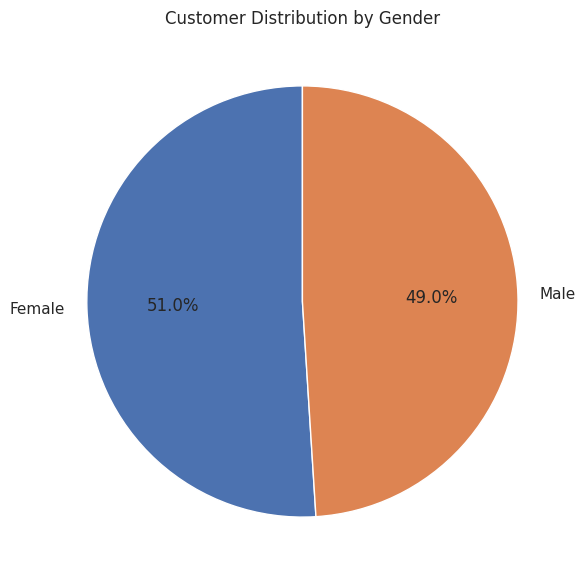

In [16]:
plt.figure(figsize=(7, 7))

plt.pie(
    gender_count,
    labels=gender_count.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Customer Distribution by Gender')
plt.show()

In [17]:
# Divide customers into age groups
df['Age Group'] = pd.cut(
    df['Age'],
    bins=[0, 18, 25, 35, 45, 55, 100],
    labels=['Below 18', '18-25', '26-35', '36-45', '46-55', 'Above 55']
)

age_group_sales = df.groupby(
    'Age Group', observed=False
)['Total Amount'].sum()

print("Sales by Age Group:")
display(age_group_sales)

Sales by Age Group:


,Total Amount
Age Group,
Below 18,11215
18-25,73335
26-35,98480
36-45,91870
46-55,100690
Above 55,80410


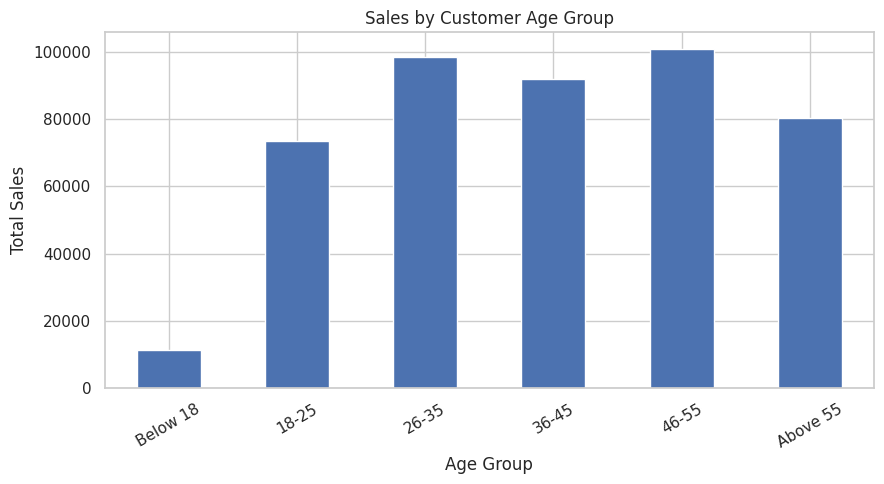

In [18]:
plt.figure(figsize=(9, 5))

age_group_sales.plot(kind='bar')

plt.title('Sales by Customer Age Group')
plt.xlabel('Age Group')
plt.ylabel('Total Sales')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

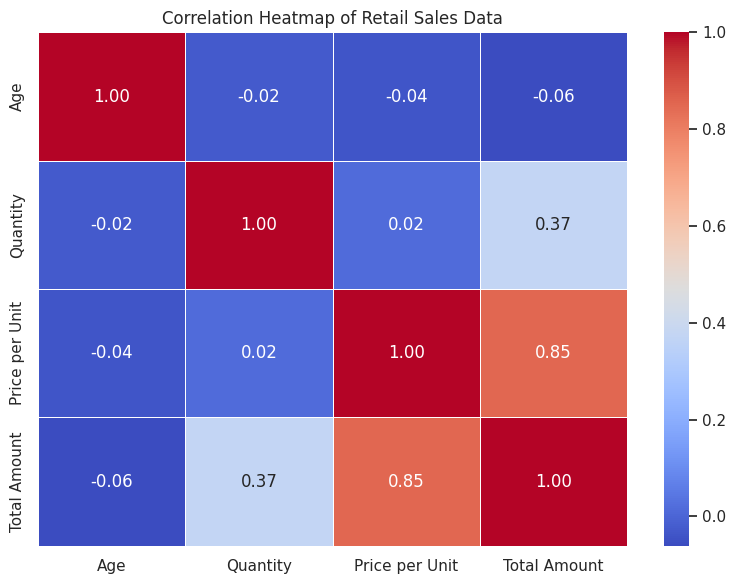

In [19]:
# Select numerical columns
numeric_data = df[
    ['Age', 'Quantity', 'Price per Unit', 'Total Amount']
]

# Calculate correlation
correlation = numeric_data.corr()

# Create heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    linewidths=0.5,
    fmt='.2f'
)

plt.title('Correlation Heatmap of Retail Sales Data')
plt.tight_layout()
plt.show()

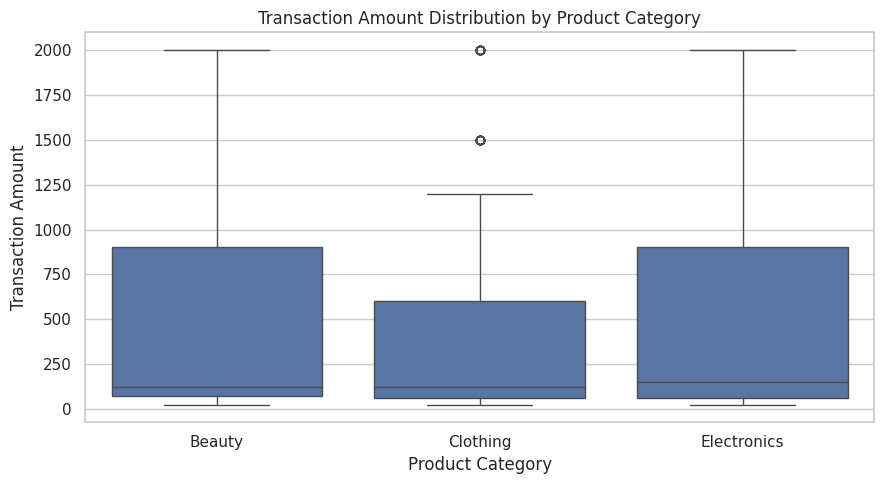

In [21]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='Product Category',
    y='Total Amount'
)

plt.title('Transaction Amount Distribution by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Transaction Amount')
plt.tight_layout()
plt.show()

Total Sales by Gender:


,Total Amount
Gender,
Female,232840
Male,223160


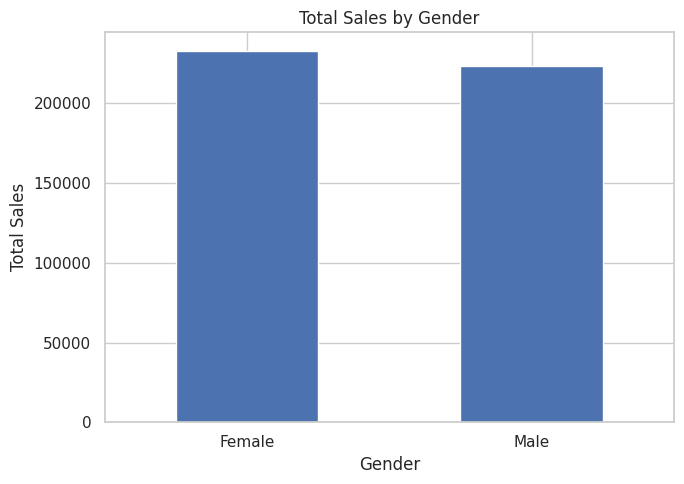

In [22]:
# Calculate total sales by gender
gender_sales = df.groupby('Gender')['Total Amount'].sum()

print("Total Sales by Gender:")
display(gender_sales)

# Create bar chart
plt.figure(figsize=(7, 5))

gender_sales.plot(kind='bar')

plt.title('Total Sales by Gender')
plt.xlabel('Gender')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [23]:
print("Correlation between numerical variables:")
display(correlation)

Correlation between numerical variables:


,Age,Quantity,Price per Unit,Total Amount
Age,1.000000,-0.023737,-0.038423,-0.060568
Quantity,-0.023737,1.000000,0.017501,0.373707
Price per Unit,-0.038423,0.017501,1.000000,0.851925
Total Amount,-0.060568,0.373707,0.851925,1.000000


In [24]:
# Rank product categories by quantity sold
top_categories = (
    df.groupby('Product Category')['Quantity']
    .sum()
    .sort_values(ascending=False)
)

print("Product Categories Ranked by Quantity Sold:")
display(top_categories)

Product Categories Ranked by Quantity Sold:


,Quantity
Product Category,
Clothing,894
Electronics,849
Beauty,771


### Dataset Overview and Data Quality

The retail sales dataset contains 1,000 transactions and 9 original columns, including transaction details, customer information, product categories, quantities, prices and total sales amounts.

The initial data quality assessment identified no missing values or duplicate records. The Date column was converted into datetime format to support monthly and quarterly sales analysis. Additional Month, Quarter and Age Group columns were created for further analysis.

The dataset was suitable for exploratory analysis without requiring missing-value imputation or duplicate removal.

### Descriptive Statistics

The descriptive analysis showed that the average customer age was 41.39 years, with a median age of 42 years. The average quantity purchased per transaction was 2.51 units, while the median quantity was 3 units.

The average price per unit was 179.89, whereas the median was 50. This difference suggests that higher-priced products influence the average.

The average transaction amount was 456, compared with a median of 135. The standard deviation of transaction amounts was approximately 560, indicating considerable variation in transaction values.

These results suggest that customer spending differs substantially across transactions.

### Sales by Product Category

Electronics generated the highest total revenue of 156,905, followed closely by Clothing with 155,580. Beauty recorded the lowest revenue of 143,515.

The difference between Electronics and Clothing was relatively small, indicating similar revenue contributions from these two categories. Although Beauty generated the lowest sales, it still contributed substantially to overall revenue.

The business should monitor demand across all three categories while identifying opportunities to improve the performance of lower-revenue categories.

### Monthly Sales Trend

The monthly sales analysis revealed noticeable fluctuations throughout 2023. May recorded the highest revenue of 53,150, followed by October with 46,580.

September recorded the lowest revenue of 23,620, while March had the second-lowest revenue of 28,990.

Sales increased sharply from April to May before declining in June. Another substantial decline occurred in September, followed by a strong recovery in October.

These fluctuations suggest that the business should investigate periods of low sales and examine whether promotional activities, customer demand or product availability contributed to the differences.

### Quarterly Sales Trend

The quarterly analysis showed that Q4 generated the highest revenue of 126,190, followed by Q2 with 123,735.

Q1 recorded sales of 110,030, while Q3 had the lowest quarterly revenue of 96,045.

Revenue increased from Q1 to Q2, declined during Q3 and recovered strongly in Q4. This indicates that sales performance varied considerably across the four quarters.

The business could examine the reasons for weaker performance in Q3 and use the findings to improve future quarterly sales planning.

### Customer Gender Distribution

The dataset contains 510 transactions associated with female customers and 490 transactions associated with male customers.

Female customers accounted for 51% of the transactions, while male customers accounted for 49%.

The difference is relatively small, suggesting a nearly balanced transaction distribution between the two gender groups.

However, transaction frequency alone does not indicate which group generated higher revenue. A separate gender-wise revenue analysis is needed to compare their total spending.

### Sales by Customer Age Group

Customers aged 46–55 generated the highest revenue of 100,690, followed closely by customers aged 26–35, who contributed 98,480.

Customers aged 36–45 generated 91,870, while customers above 55 contributed 80,410. The 18–25 age group generated 73,335.

Customers below 18 contributed the lowest revenue of 11,215.

The results indicate that customers aged 46–55 are an important revenue-generating segment in this dataset. However, differences in total sales may also reflect the number of transactions within each age group.

The business could investigate purchasing preferences across age groups to develop more targeted marketing strategies.

### Correlation Analysis

The correlation heatmap examines the relationships between Age, Quantity, Price per Unit and Total Amount.

Total Amount is calculated from Quantity and Price per Unit, so both variables are directly related to transaction value. The heatmap helps examine how strongly these relationships appear across the dataset.

Age is also included to investigate whether customer age has a linear relationship with purchasing quantity, product prices or transaction amounts.

The correlation analysis provides an overview of numerical relationships, but correlation alone does not establish a cause-and-effect relationship.

### Transaction Amount Distribution by Product Category

The box plot compares the distribution of transaction amounts across Beauty, Clothing and Electronics.

This visualisation helps examine differences in median transaction values, spending ranges and the presence of unusually high transaction amounts.

The distribution of transaction values provides additional information beyond total category revenue. Categories with similar total revenue may still have different patterns of customer spending.

These findings can support further investigation into product pricing and purchasing behaviour.

### Best-Selling Product Categories and Dataset Limitation

The dataset contains product category information but does not include individual product names or product identifiers.

Therefore, it is possible to compare sales revenue and quantities across Beauty, Clothing and Electronics, but it is not possible to identify the top 10 individual best-selling products accurately.

The available category-level analysis provides useful information about overall product category performance. A more detailed product-level dataset would be required to analyse individual best-selling products.

## Business Recommendations

Based on the exploratory analysis of the retail sales dataset, the following recommendations can be considered:

1. **Focus on high-performing categories:** Electronics generated the highest revenue. The business should maintain adequate stock and monitor demand for electronic products.

2. **Investigate monthly sales fluctuations:** May recorded the highest sales, while September recorded the lowest. The business should examine possible reasons for the September decline and consider suitable promotional campaigns.

3. **Strengthen customer targeting:** Customers aged 46–55 contributed the highest sales. Targeted offers and marketing campaigns could help maintain engagement with this customer group.

4. **Improve quarterly sales performance:** Q3 had the lowest quarterly revenue. The business could review its promotional activities, product availability and customer engagement during this period.

5. **Use transaction patterns for planning:** The category comparison and transaction amount distribution can help the business review pricing, product demand and inventory decisions.

## Conclusion

This project analysed a retail sales dataset containing 1,000 transactions recorded during 2023. The analysis involved data inspection, descriptive statistics, monthly and quarterly sales trends, product category performance, customer demographics and numerical correlation analysis.

The results showed that Electronics generated the highest category revenue, May was the strongest month, and Q4 recorded the highest quarterly sales. Customers aged 46–55 contributed the highest revenue among the age groups.

The analysis provides a basic understanding of retail sales patterns and customer purchasing behaviour. However, the dataset does not contain individual product names or product IDs, so a top 10 individual product analysis could not be performed. The findings can help identify areas where the business may improve sales planning, inventory management and marketing strategies.